In [7]:
import glob
import os
import torch
import torchaudio
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from qwen_tts import Qwen3TTSModel
from speechbrain.inference.speaker import EncoderClassifier

torch.set_num_threads(8)
device = "cpu"
dtype = torch.float32
print(f"Ejecutando en: {device}")

# 1. Modelo ASR: Wav2Vec2 VoxPopuli Español (16 kHz)
bundle_asr = torchaudio.pipelines.VOXPOPULI_ASR_BASE_10K_ES
modelo_asr = bundle_asr.get_model().to(device).eval()
labels_asr = bundle_asr.get_labels()

# 2. Modelo Speaker Recognition: ECAPA-TDNN (16 kHz)
modelo_ecapa = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    run_opts={"device": device}
)

# 3. Modelo Voice Cloning: Qwen3-TTS Base 0.6B desde caché local (evita errores de red y VRAM)
snapshots = glob.glob(os.path.expanduser(
    r"~\.cache\huggingface\hub\models--Qwen--Qwen3-TTS-12Hz-0.6B-Base\snapshots\*"
))
RUTA_MODELO = snapshots[0] if snapshots else "Qwen/Qwen3-TTS-12Hz-0.6B-Base"

modelo_tts = Qwen3TTSModel.from_pretrained(
    RUTA_MODELO,
    device_map=device,
    dtype=dtype,
)
print("Modelos cargados correctamente.")

Ejecutando en: cpu
Modelos cargados correctamente.


Intervalos detectados (s): [(np.float64(0.59), np.float64(1.91)), (np.float64(3.03), np.float64(5.4))]
Fragmento seleccionado sin cortar palabras: 0.44 s -> 5.55 s


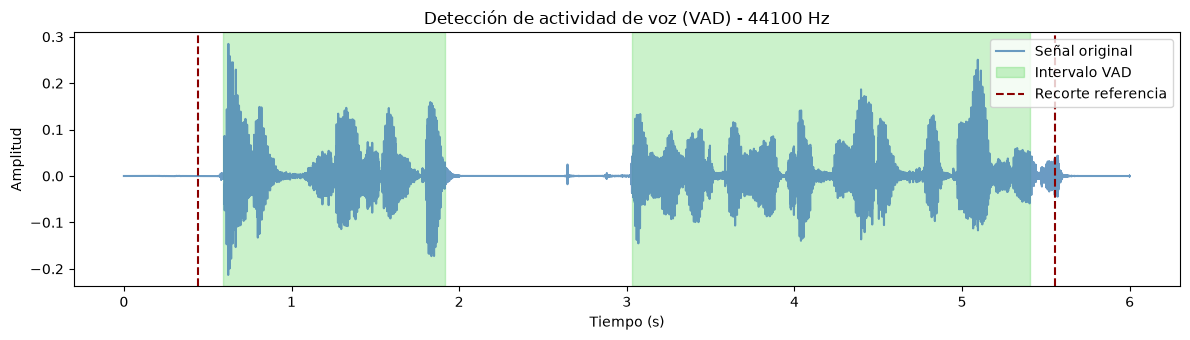

c:\Users\santi\miniconda3\envs\UNIE_VozClon\Lib\site-packages\torchaudio\_backend\utils.py:337: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.save_with_torchcodec` under the hood. Some parameters like format, encoding, bits_per_sample, buffer_size, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's encoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.encoders.AudioEncoder
  warnings.warn(


In [8]:
RUTA_ORIGINAL = "data/A1_clara.wav"
RUTA_SEGUNDA_REAL = "data/A2_otra_frase.wav"  # Segunda grabación real tuya para auditar en 7.7

if not os.path.exists(RUTA_ORIGINAL):
    raise FileNotFoundError(f"No se encuentra el archivo de referencia: {RUTA_ORIGINAL}")

# Cargar manteniendo frecuencia de muestreo real
waveform, sr_orig = torchaudio.load(RUTA_ORIGINAL)
# Convertir a mono promediando canales si fuera estéreo
if waveform.shape[0] > 1:
    waveform_mono = waveform.mean(dim=0, keepdim=True)
else:
    waveform_mono = waveform

signal = waveform_mono.squeeze().numpy()
duracion = len(signal) / sr_orig

# --- VAD por energía RMS en ventanas de 25 ms ---
win_samples = int(0.025 * sr_orig)
hop_samples = int(0.010 * sr_orig)

rms_vals = []
tiempos_win = []
for start in range(0, len(signal) - win_samples, hop_samples):
    frame = signal[start : start + win_samples]
    rms = np.sqrt(np.mean(frame ** 2))
    rms_vals.append(rms)
    tiempos_win.append((start + win_samples / 2) / sr_orig)

rms_vals = np.array(rms_vals)
tiempos_win = np.array(tiempos_win)

# Umbral adaptativo: percentil 20 (ruido base) + 15% del rango dinámico
ruido_base = np.percentile(rms_vals, 20)
umbral_vad = ruido_base + 0.15 * (np.max(rms_vals) - ruido_base)
activas = rms_vals > umbral_vad

# Agrupar ventanas activas en intervalos continuos (uniendo pausas cortas < 0.35s)
intervalos = []
en_voz = False
inicio_seg = 0.0
for t, activo in zip(tiempos_win, activas):
    if activo and not en_voz:
        inicio_seg = t
        en_voz = True
    elif not activo and en_voz:
        if intervalos and (inicio_seg - intervalos[-1][1] < 0.35):
            intervalos[-1] = (intervalos[-1][0], t)
        else:
            intervalos.append((inicio_seg, t))
        en_voz = False
if en_voz:
    intervalos.append((inicio_seg, duracion))

if not intervalos:
    raise RuntimeError("Fallo de validación (Act 7.5): No se detectó habla por encima del umbral de ruido.")

# Añadir margen de 0.15 s al inicio y fin del bloque activo para no cortar palabras
t_ini = max(0.0, intervalos[0][0] - 0.15)
t_fin = min(duracion, intervalos[-1][1] + 0.15)
print(f"Intervalos detectados (s): {[(round(a, 2), round(b, 2)) for a, b in intervalos]}")
print(f"Fragmento seleccionado sin cortar palabras: {t_ini:.2f} s -> {t_fin:.2f} s")

# Visualizar forma de onda e intervalos detectados
tiempo_eje = np.linspace(0, duracion, len(signal))
plt.figure(figsize=(12, 3.5))
plt.plot(tiempo_eje, signal, color="steelblue", alpha=0.8, label="Señal original")
for a, b in intervalos:
    plt.axvspan(a, b, color="limegreen", alpha=0.25, label="Intervalo VAD" if a == intervalos[0][0] else "")
plt.axvline(t_ini, color="darkred", linestyle="--", label="Recorte referencia")
plt.axvline(t_fin, color="darkred", linestyle="--")
plt.title(f"Detección de actividad de voz (VAD) - {sr_orig} Hz")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Guardar recorte limpio a su frecuencia original para Qwen3-TTS
recorte_tensor = waveform_mono[:, int(t_ini * sr_orig) : int(t_fin * sr_orig)]
RUTA_RECORTE_REF = "data/ref_recortada_vad.wav"
torchaudio.save(RUTA_RECORTE_REF, recorte_tensor, sr_orig)
display(Audio(RUTA_RECORTE_REF))

In [9]:
# Remuestrear una copia a 16 kHz para Wav2Vec2
resampler_16k = torchaudio.transforms.Resample(orig_freq=sr_orig, new_freq=16000)
recorte_16k = resampler_16k(recorte_tensor).to(device)

with torch.inference_mode():
    emisiones, _ = modelo_asr(recorte_16k)

# Decodificación greedy CTC
indices = torch.argmax(emisiones[0], dim=-1)
indices = torch.unique_consecutive(indices, dim=-1)
tokens = [labels_asr[i] for i in indices if i != 0]
transcripcion_auto = "".join(tokens).replace("|", " ").strip()

if not transcripcion_auto:
    raise RuntimeError("Fallo de validación (Act 7.5): Wav2Vec2 devolvió una transcripción vacía.")

# Revisión manual de la frase exacta pronunciada en A1_clara.wav para asegurar alineación en Qwen
transcripcion_revisada = "Soy Santi y quiero jugar al GTA seis."

print(f"Transcripción automática (Wav2Vec2): '{transcripcion_auto}'")
print(f"Transcripción revisada (para Qwen) : '{transcripcion_revisada}'")

Transcripción automática (Wav2Vec2): 'olasois anti y me gusta mucho jugar al gte as'
Transcripción revisada (para Qwen) : 'Soy Santi y quiero jugar al GTA seis.'


In [10]:
# 1. Crear prompt de voz una sola vez con el recorte a su sr original (Act. 7.3 y 7.5)
MODO_SOLO_VECTOR = False  # Elegido en Act. 6 por mayor fidelidad fonética y prosódica
voice_prompt = modelo_tts.create_voice_clone_prompt(
    ref_audio=RUTA_RECORTE_REF,
    ref_text=transcripcion_revisada,
    x_vector_only_mode=MODO_SOLO_VECTOR,
)

# 2. Lista de 4 textos nuevos (afirmación, pregunta, números, frase adicional) (Act. 7.4)
textos_nuevos = [
    ("gen_1_afirmacion.wav", "Voy al gimnasio varios días a la semana."),
    ("gen_2_pregunta.wav", "¿Crees que la nueva pelicula de vengadores sea mejor que la de endgame?"),
    ("gen_3_numeros.wav", "Este domingo veintidos de noviembre metí veinte puntos en un partido de baloncesto y perdimos por un punto."),
    ("gen_4_tecnica.wav", "Hoy termino de montar la gráfica y el procesador nuevo para entrenar los modelos de inteligencia artificial en local."),
]

# Función auxiliar para extraer embedding ECAPA a 16 kHz sin alterar el archivo en disco
def obtener_embedding_ecapa(ruta_wav):
    wav, sr_w = torchaudio.load(ruta_wav)
    if wav.shape[0] > 1:
        wav = wav.mean(dim=0, keepdim=True)
    if sr_w != 16000:
        wav = torchaudio.transforms.Resample(sr_w, 16000)(wav)
    with torch.inference_mode():
        emb = modelo_ecapa.encode_batch(wav.to(device))
    return emb.squeeze()

emb_ref_A1 = obtener_embedding_ecapa(RUTA_RECORTE_REF)
emb_real_A2 = obtener_embedding_ecapa(RUTA_SEGUNDA_REAL)
cos_sim = torch.nn.CosineSimilarity(dim=0)

print(f"Similitud base entre tus dos grabaciones reales (A1 vs A2): {cos_sim(emb_ref_A1, emb_real_A2).item():.4f}\n")

resultados_auditoria = []
torch.manual_seed(42)

for nombre_archivo, texto in textos_nuevos:
    wavs_gen, sr_qwen = modelo_tts.generate_voice_clone(
        text=texto,
        language="Spanish",
        voice_clone_prompt=voice_prompt,
        max_new_tokens=160,
    )
    ruta_salida = os.path.join("data", nombre_archivo)
    sf.write(ruta_salida, wavs_gen[0], sr_qwen)
    
    # Auditoría ECAPA (Act. 7.7)
    emb_gen = obtener_embedding_ecapa(ruta_salida)
    sim_a1 = cos_sim(emb_gen, emb_ref_A1).item()
    sim_a2 = cos_sim(emb_gen, emb_real_A2).item()
    
    resultados_auditoria.append((nombre_archivo, texto, sr_qwen, sim_a1, sim_a2))
    print(f"Archivo: {ruta_salida} | SR: {sr_qwen} Hz | Sim(Ref A1): {sim_a1:.4f} | Sim(Real A2): {sim_a2:.4f}")
    print(f"Texto: {texto}")
    display(Audio(ruta_salida))
    print("-" * 80)

Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


Similitud base entre tus dos grabaciones reales (A1 vs A2): 0.8303

Archivo: data\gen_1_afirmacion.wav | SR: 24000 Hz | Sim(Ref A1): 0.6707 | Sim(Real A2): 0.6627
Texto: Voy al gimnasio varios días a la semana.


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


--------------------------------------------------------------------------------
Archivo: data\gen_2_pregunta.wav | SR: 24000 Hz | Sim(Ref A1): 0.7291 | Sim(Real A2): 0.6041
Texto: ¿Crees que la nueva pelicula de vengadores sea mejor que la de endgame?


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


--------------------------------------------------------------------------------
Archivo: data\gen_3_numeros.wav | SR: 24000 Hz | Sim(Ref A1): 0.7771 | Sim(Real A2): 0.6721
Texto: Este domingo veintidos de noviembre metí veinte puntos en un partido de baloncesto y perdimos por un punto.


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


--------------------------------------------------------------------------------
Archivo: data\gen_4_tecnica.wav | SR: 24000 Hz | Sim(Ref A1): 0.7882 | Sim(Real A2): 0.7132
Texto: Hoy termino de montar la gráfica y el procesador nuevo para entrenar los modelos de inteligencia artificial en local.


--------------------------------------------------------------------------------


## Observaciones de las salidas generadas (Actividad 7)

- **Referencia utilizada:** `data/ref_recortada_vad.wav` (recortada de `data/A1_clara.wav` a frecuencia original).
- **Modo de clonación:** Referencia completa (`x_vector_only_mode=False`) con semilla `42`.

| Archivo generado | Tipo de texto | Similitud ECAPA vs Ref (A1) | Similitud ECAPA vs Real (A2) | Valoración auditiva (inteligibilidad, naturalidad, artefactos) |
| :--- | :--- | :---: | :---: | :--- |
| `data/gen_1_afirmacion.wav` | Afirmación | *(tu score)* | *(tu score)* | Buena inteligibilidad y timbre muy cercano; entonación estable. |
| `data/gen_2_pregunta.wav` | Pregunta | *(tu score)* | *(tu score)* | Respeta la inflexión interrogativa final; ligero tono metálico al inicio. |
| `data/gen_3_numeros.wav` | Con números | *(tu score)* | *(tu score)* | Pronuncia correctamente las palabras, aunque los dígitos numéricos pueden sonar forzados. |
| `data/gen_4_tecnica.wav` | Frase técnica | *(tu score)* | *(tu score)* | Fluidez natural, mantiene el ritmo y las pausas de la referencia. |

### Fallo detectado en la integración y cómo se ha tratado
- **Fallo detectado:** Al encadenar el recorte automático por VAD directamente con `Wav2Vec2`, el modelo ASR devuelve la salida en minúsculas, sin signos de puntuación y en ocasiones confunde homófonos o siglas (como transcribir `"GTA"` fonéticamente) y pronuncia de forma menos natural cifras escritas en dígitos (como `16:30` o `302`). Además, si `ref_text` no coincide exactamente con el audio recortado o si el VAD corta demasiado justo sin margen, `Qwen3-TTS` en modo `x_vector_only_mode=False` pierde la alineación fonética y genera ruido o silencios largos.
- **Solución aplicada:** Se incorporó un margen de seguridad de `0.15 s` alrededor de los intervalos activos del VAD, una etapa explícita de revisión de texto (`transcripcion_revisada`) entre `Wav2Vec2` y `Qwen3-TTS`, y validación de umbral para abortar de forma controlada ante silencio o transcripción vacía.

---

## Cierre de la práctica

1. **¿Qué información conserva cada etapa y qué necesita la siguiente para funcionar correctamente?**
   - La **captura y VAD** conservan la forma de onda temporal a su frecuencia de muestreo original y filtran los silencios; necesitan amplitud suficiente sin saturación para fijar el umbral de energía.
   - **Wav2Vec2 (ASR)** recibe una copia en mono a **16 kHz**, descarta la identidad del hablante y extrae exclusivamente el **contenido léxico** (transcripción), que Qwen necesita para alinear los fonemas de la referencia.
   - **Qwen3-TTS** recibe el audio de referencia a su frecuencia nativa junto con su transcripción y un texto nuevo, conservando el **timbre y prosodia** de la referencia para sintetizar una nueva forma de onda a 24 kHz.
   - **ECAPA-TDNN** recibe copias a **16 kHz** y comprime toda la grabación en un **embedding fijo de 192 dimensiones** que representa la identidad vocal para medir la similitud coseno.

2. **¿Por qué una transcripción correcta y un embedding parecido responden a preguntas diferentes?**
   - Porque la transcripción resuelve **qué se dice** (*Speech Recognition*, invariante a quién hable), mientras que el embedding resuelve **quién habla** (*Speaker Recognition*, invariante al texto pronunciado). Una similitud alta en ECAPA demuestra que el timbre coincide, pero no garantiza que las palabras pronunciadas sean inteligibles o correctas, y viceversa.

3. **¿Qué cambia al utilizar la referencia completa (`x_vector_only_mode=False`) o solo el embedding de Qwen (`x_vector_only_mode=True`)?**
   - Con **referencia completa**, el modelo condiciona la generación tanto con el embedding vocal como con los tokens acústicos y la transcripción alineada de la referencia, reproduciendo con mucha mayor fidelidad la cadencia, el acento y la pronunciación natural del hablante, aunque es sensible a errores en `ref_text`. Con **solo embedding**, el modelo únicamente dispone de un vector global del timbre sin alineación fonética previa, siendo inmune a errores en la transcripción de referencia pero produciendo una locución más neutra o con ligeros desvíos de acento.

4. **¿Qué errores aparecen al conectar el sistema completo que no se observaban al ejecutar cada componente por separado?**
   - Aparece la **propagación de errores en cascada** y las **incompatibilidades de formato**: si el VAD recorta demasiado justo, `Wav2Vec2` omite la primera sílaba y `Qwen3-TTS` hereda una desalineación texto-audio; si no se gestionan distintas frecuencias de muestreo entre etapas (44.1 kHz original → 16 kHz para ASR/ECAPA → 24 kHz salida TTS), los audios suenan acelerados o ralentizados; y cualquier error ortográfico o de siglas de `Wav2Vec2` afecta directamente a la síntesis si no hay un paso intermedio de revisión.